# Классификация текста и анализ ошибок

Метрики берутся из папки `reports/metrics`. Основная метрика macro-F1, дополнительно accuracy.

In [1]:
import json, os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image
from src.config import FIGURES, LABEL_NAMES_RU, LABELS, ROOT
from src.evaluate import METRICS
from src.error_analysis import ensemble_frame, errors_table
from src.data.profanity import mask
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 120)
load = lambda name: json.loads((METRICS / f'{name}.json').read_text(encoding='utf-8'))

## 1. Сравнение моделей

Трансформеры (rubert) приведены только для сравнения.

In [2]:
names = {
    'tfidf_nb': 'TF-IDF + Complement NB', 'tfidf_logreg': 'TF-IDF + LogReg', 'tfidf_svm': 'TF-IDF + LinearSVC',
    'bigru_navec': 'BiGRU + navec', 'textcnn_navec': 'TextCNN + navec', 'ensemble': 'Ансамбль',
    'rubert_tiny2': 'rubert-tiny2 (трансформер)', 'rubert_base': 'ruBert-base (трансформер)',
}
rows = []
for key, title in names.items():
    r = load(key)
    rows.append({'модель': title, 'val macro-F1': r.get('val_macro_f1') or r.get('best_val_macro_f1'),
                 'test macro-F1': r['test']['macro_f1'], 'test accuracy': r['test']['accuracy'],
                 'F1 оскорб.': r['test']['per_class']['insult']['f1'], 'F1 токсич.': r['test']['per_class']['toxic']['f1'],
                 '2ch F1': r['external_2ch_binary']['f1_toxic']})
pd.DataFrame(rows).set_index('модель')

,val macro-F1,test macro-F1,test accuracy,F1 оскорб.,F1 токсич.,2ch F1
модель,,,,,,
TF-IDF + Complement NB,0.8033,0.8090,0.9147,0.7322,0.7371,0.6846
TF-IDF + LogReg,0.8996,0.8970,0.9629,0.8600,0.8448,0.6571
TF-IDF + LinearSVC,0.8987,0.8975,0.9642,0.8606,0.8454,0.5841
BiGRU + navec,0.8727,0.8681,0.9490,0.8096,0.8165,0.6130
TextCNN + navec,0.8873,0.8805,0.9547,0.8321,0.8286,0.6223
Ансамбль,0.9089,0.9046,0.9665,0.8726,0.8536,0.6237
rubert-tiny2 (трансформер),0.9010,0.9000,0.9629,0.8629,0.8516,0.6745
ruBert-base (трансформер),0.9210,0.9242,0.9724,0.8915,0.8916,0.6641


## 2. Ансамбль

Вероятности пяти моделей усредняются с весами. Веса подобраны на val, проверка на test.

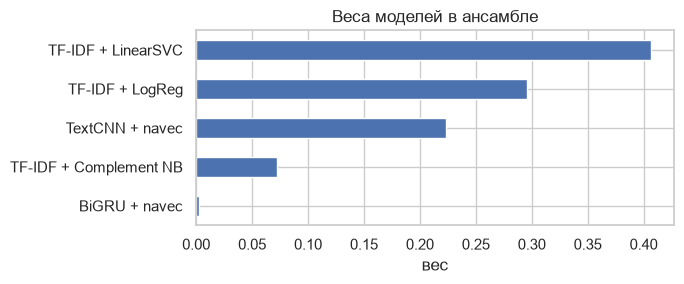

,val,test
лучшая модель,0.8996,0.8975
ансамбль,0.9089,0.9046


In [3]:
ens = load('ensemble')['stages']
w = pd.Series(ens['weights']).rename(index=names).sort_values()
ax = w.plot.barh(figsize=(7, 3), color='#4C72B0'); ax.set_xlabel('вес'); ax.set_title('Веса моделей в ансамбле')
plt.tight_layout(); plt.savefig(FIGURES / 'ensemble_weights.png', dpi=120); plt.show()
pd.DataFrame({'лучшая модель': {'val': max(v['val'] for v in ens['single_models'].values()), 'test': max(v['test'] for v in ens['single_models'].values())},
              'ансамбль': ens['blend']}).T

Больше всего вес у SVM, логистической регрессии и TextCNN. BiGRU почти не используется, он быстро переобучается и ничего не добавляет к TextCNN.

## 3. Обработка после классификации

Сдвиг порогов классов на val не дал улучшения, лучший сдвиг нулевой.

Метка "сомнительно": если уверенность модели ниже порога, сообщение не классифицируется автоматически. Порог подобран на val так, чтобы таких сообщений было около 5%.

In [4]:
d = ens['doubtful']
print(f"порог: {d['threshold']:.3f}")
print(f"на test: сомнительных {d['test']['doubtful_share']:.1%}, в них {d['test']['errors_caught']:.1%} ошибок, "
      f"macro-F1 на остальных {d['test']['macro_f1_confident']:.4f} (без обработки {ens['blend']['test']:.4f})")
pd.DataFrame(d['curve_test']).set_index('threshold')

порог: 0.692
на test: сомнительных 4.8%, в них 53.5% ошибок, macro-F1 на остальных 0.9439 (без обработки 0.9046)


,doubtful_share,macro_f1_confident,errors_caught
threshold,,,
0.40,0.0003,0.9051,0.0048
0.45,0.0015,0.9062,0.0227
0.50,0.0054,0.9097,0.0764
0.55,0.0148,0.9182,0.1981
0.60,0.0250,0.9269,0.3174
0.65,0.0367,0.9355,0.4368
0.70,0.0502,0.9462,0.5561
0.75,0.0658,0.9554,0.6563
0.80,0.0881,0.9622,0.7279


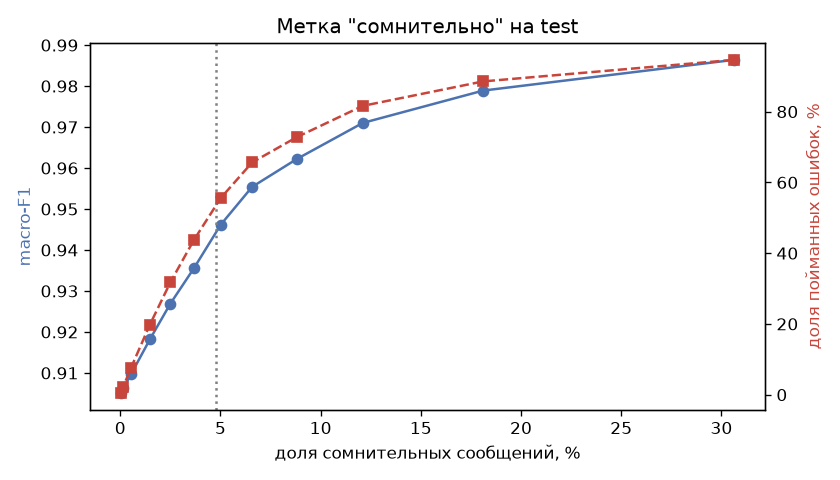

In [5]:
Image(filename=str(FIGURES / 'ensemble_doubtful.png'))

Чем больше сообщений помечено как сомнительные, тем больше ошибок в них попадает.

## 4. Анализ ошибок

In [6]:
df = ensemble_frame()
err = errors_table(df)
print(f'ошибок: {len(err)} из {len(df)} ({len(err) / len(df):.1%})')
pairs = err.groupby(['label', 'pred']).size().sort_values(ascending=False).rename('ошибок').reset_index()
pairs['истинный класс'] = pairs['label'].map(LABEL_NAMES_RU)
pairs['предсказанный класс'] = pairs['pred'].map(LABEL_NAMES_RU)
pairs[['истинный класс', 'предсказанный класс', 'ошибок']]

ошибок: 838 из 24998 (3.4%)


,истинный класс,предсказанный класс,ошибок
0,оскорбительное,нейтральное,238
1,токсичное,оскорбительное,174
2,оскорбительное,токсичное,149
3,нейтральное,оскорбительное,148
4,токсичное,нейтральное,76
5,нейтральное,токсичное,53


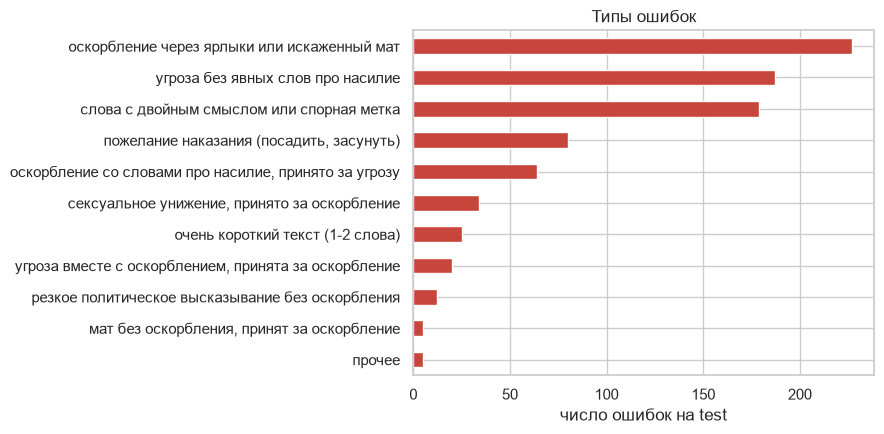

,ошибок
category,
оскорбление через ярлыки или искаженный мат,227
угроза без явных слов про насилие,187
слова с двойным смыслом или спорная метка,179
"пожелание наказания (посадить, засунуть)",80
"оскорбление со словами про насилие, принято за угрозу",64
"сексуальное унижение, принято за оскорбление",34
очень короткий текст (1-2 слова),25
"угроза вместе с оскорблением, принята за оскорбление",20
резкое политическое высказывание без оскорбления,12


In [7]:
cats = err.groupby('category').size().sort_values(ascending=False).rename('ошибок').to_frame()
fig, ax = plt.subplots(figsize=(9, 4.5))
cats['ошибок'][::-1].plot.barh(ax=ax, color='#C8453B'); ax.set_xlabel('число ошибок на test'); ax.set_ylabel('')
ax.set_title('Типы ошибок'); plt.tight_layout(); plt.savefig(FIGURES / 'error_categories.png', dpi=120); plt.show()
cats

Примеры:

In [8]:
for cat in cats.index:
    print(f'\n{cat}')
    for r in err[err.category == cat].sample(min(3, (err.category == cat).sum()), random_state=0).itertuples():
        print(f"   [{LABEL_NAMES_RU[r.label]}, предсказано {LABEL_NAMES_RU[r.pred]}] {mask(r.text_raw[:110])}")


оскорбление через ярлыки или искаженный мат
   [оскорбительное, предсказано нейтральное] скатертью дорожка царь врунов,ученик иуды и гебельса,на прямую в лефортово,под охрану пожизненую ,как вы и хот
   [оскорбительное, предсказано нейтральное] даже в берлине, г путин не даёт покоя, долбеням, ну смешно право,
   [оскорбительное, предсказано нейтральное] ну естественно,куда мне, вы же жидо христьянская истена в последней инстанции

угроза без явных слов про насилие
   [токсичное, предсказано нейтральное] на нож всех
   [токсичное, предсказано нейтральное] ее муж брасил видать сасала плохо
   [токсичное, предсказано оскорбительное] гнида тебя подонка пешать пора

слова с двойным смыслом или спорная метка
   [нейтральное, предсказано токсичное] поставьте на 180 я разобью и я больше не буду бить
   [нейтральное, предсказано токсичное] лучше к стенке
   [нейтральное, предсказано оскорбительное] эти твари живучие😂

пожелание наказания (посадить, засунуть)
   [оскорбительное, предсказано ток

Больше всего ошибок между оскорбительными и токсичными сообщениями. Модель ориентируется на отдельные слова, поэтому угроза без слов про насилие часто определяется как оскорбление.

Также модель ошибается на искаженном мате, словах с двойным смыслом и очень коротких сообщениях.

## 5. Уверенные ошибки

Просмотрено 40 случайных ошибок, где модель была уверена на 95% и больше.

In [9]:
review = pd.read_csv(ROOT / 'resources' / 'confident_errors_review.csv')
display(review['verdict'].value_counts().rename('случаев').to_frame())
review[review.verdict == 'метка датасета спорна'].head(10)[['text', 'label', 'pred']]

,случаев
verdict,
права разметка,21
метка датасета спорна,19


,text,label,pred
0,"слава вдв!!!долой россгвардию-недоносков,живущих за счёт налогоплательщиков и их же избивающих!абсолютно ненужная го...",neutral,insult
1,сразу видно козлы с овцами.,neutral,insult
3,а дебилы - то в школу не ходят . люди поднимайтесь !,neutral,insult
4,ноино ту т аz на кол суку пым не,insult,toxic
8,"слушай! противник всего, кроме пи****в. иди ты в свою толерантную европу, со своими двойными стандартами. и любуйся ...",toxic,insult
10,"покайся и сдохни, тварь, не порть атмосферу.",insult,toxic
16,е** ны е мажоры чтоб вы сдохли,insult,toxic
20,надо раком их тварей поставить чтобы не видели балого света.,insult,toxic
21,ты еб***й кусок гавна бл**ь... тебя пи*****а зачали в то время. видать зачали тебя га***н по пьяне и на чердаке. пот...,toxic,insult
22,"вы недоношенные дебилы, он все разворовал, продал, а вы ублюдки и подхалимы жопу лижите. лилипутин враг народа его с...",toxic,insult


Примерно в половине случаев скорее ошибается разметка датасета, а не модель.

## 6. Проверочные фразы

In [10]:
probe_rows = {names[k]: {g: v['accuracy'] for g, v in load(k)['probes'].items()} for k in names}
(pd.DataFrame(probe_rows).T * 100).round(0).astype(int).astype(str) + '%'

,мат без адресата,политика без грубости,бытовое нейтральное,оскорбление без мата,угроза без мата
TF-IDF + Complement NB,53%,90%,100%,90%,60%
TF-IDF + LogReg,13%,100%,100%,70%,40%
TF-IDF + LinearSVC,20%,100%,100%,50%,30%
BiGRU + navec,20%,100%,100%,90%,70%
TextCNN + navec,20%,100%,100%,90%,60%
Ансамбль,20%,100%,100%,70%,60%
rubert-tiny2 (трансформер),20%,100%,100%,90%,50%
ruBert-base (трансформер),20%,100%,100%,90%,60%


Фразы с матом без оскорбления почти все модели считают оскорбительными. Лучше всех с этим справляется наивный Байес. Это планируется исправить на следующем этапе.